# Modelo final, reproducción del método e interpretación (8.1 a 8.3)

Este notebook cierra el flujo de modelamiento de la Entrega final:

1. **Selección del modelo final (8.1).** Partimos de la validación cruzada anidada del notebook 05 y
   sopesamos desempeño, estabilidad e interpretabilidad. Comparamos además, de forma pareada y con
   bootstrap, el modelo elegido frente a su alternativa más interpretable (la regresión logística).
2. **Configuración definitiva y evaluación en prueba (8.1).** Curva ROC, costo según el umbral y
   calibración de las probabilidades, contrastadas con la probabilidad verdadera de la simulación.
3. **Interpretación (8.2).** SHAP a nivel de las 11 variables originales, contrastado con la estructura
   generadora de la simulación; dependencia parcial e ICE; LIME frente a SHAP en casos individuales.
4. **Tipos de error e implicaciones (8.2).** Costo por tipo de error, efecto por segmento y por género,
   y sensibilidad de la política a la matriz de costos.
5. **Coherencia de los datos de uso (8.3).** La verificación que usa la aplicación de Streamlit,
   probada sobre el conjunto de prueba y sobre un lote con deriva y errores de captura.

El modelo final se entrena con `src/modelo_final.py`, con el mismo procedimiento evaluado en la
validación anidada; aquí se carga el artefacto que también usa la aplicación. Los módulos compartidos
están en `src/` (`preprocesamiento.py`, `evaluacion.py`, `interpretacion.py`).

In [1]:
import sys
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, confusion_matrix, roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

sys.path.append("../src")
from preprocesamiento import SEED, CAT_COLS, NUM_COLS, cargar_particion, construir_pipeline
from evaluacion import ajustar_modelo, costo_medio, metricas
from interpretacion import (COLUMNAS, NOMBRES, ModeloFinal, Codificador, crear_explicador,
                            tabla_explicacion, verificar_coherencia)
from generar_datos_simulados import (generar_base, PESOS_CATEGORICOS, PESOS_NUMERICOS,
                                     SD_RUIDO_LATENTE)
import modelo_final

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 110
DIR_RES = Path("../docs/resultados")
AZUL, ROJO, VERDE, GRIS, NARANJA = "#4C78A8", "#E45756", "#54A24B", "#9D9D9D", "#F58518"

X_train, X_test, y_train_txt, y_test_txt = cargar_particion()
y_train = (y_train_txt == "malo").astype(int).to_numpy()
y_test = (y_test_txt == "malo").astype(int).to_numpy()
base_completa, p_teorica = generar_base(seed=SEED, devolver_probabilidad=True)
p_test = p_teorica[X_test.index.to_numpy()]

# El modelo final se entrena con src/modelo_final.py; si no existe, se entrena aquí
if not modelo_final.RUTA_MODELO.exists():
    modelo_final.main()
artefacto = joblib.load(modelo_final.RUTA_MODELO)
modelo = ModeloFinal(artefacto)
print("Modelo:", artefacto["nombre"], artefacto["hiperparametros"],
      f"| umbral (margen) = {artefacto['umbral']:.3f} | umbral (probabilidad) = {modelo.umbral_probabilidad:.3f}")

Modelo: SVM RBF {'gamma': 0.01, 'C': 1.0} | umbral (margen) = -0.492 | umbral (probabilidad) = 0.142


## 1. Selección del modelo final

La Tabla de selección reúne, para cada modelo avanzado y la línea base logística, lo que pide la guía:
**desempeño** (ROC-AUC y costo 5:1 en la validación anidada y en prueba), **estabilidad** (desviación
entre los 5 folds externos) e **interpretabilidad**. Las cifras vienen de las tablas que guardó el
notebook 05.

In [2]:
def separar(celda):
    """'0.490 ± 0.013' -> (0.490, 0.013)."""
    if isinstance(celda, str) and "±" in celda:
        m, d = celda.split("±")
        return float(m), float(d)
    return np.nan, np.nan

anidada = pd.read_csv(DIR_RES / "05_tabla_validacion_anidada.csv", index_col=0)
test05 = pd.read_csv(DIR_RES / "05_tabla_test.csv", index_col=0)

INTERPRETABILIDAD = {
    "Regresión logística (línea base)": "Alta: coeficientes en escala logit",
    "SVM lineal": "Alta: coeficientes (sin probabilidad)",
    "SVM RBF": "Baja: requiere SHAP o dependencia parcial",
    "SVM RBF + selección LASSO": "Baja: requiere SHAP o dependencia parcial",
    "Árbol de decisión": "Alta: reglas explícitas",
    "Random Forest": "Baja: 300 árboles",
    "Gradient Boosting": "Media-baja: árboles de un corte",
}
seleccion = pd.DataFrame(index=list(INTERPRETABILIDAD))
for col in ["ROC-AUC", "Costo medio (5:1)", "F1 (malo)", "Recall (malo)"]:
    pares = anidada.loc[seleccion.index, col].map(separar)
    seleccion[f"{col} anidada"] = [p[0] for p in pares]
    seleccion[f"desv. {col}"] = [p[1] for p in pares]
seleccion["p-valor AUC vs. logística"] = anidada.loc[seleccion.index, "p-valor (AUC)"]
seleccion["ROC-AUC test"] = test05.loc[seleccion.index, "ROC-AUC"]
seleccion["Costo test"] = test05.loc[seleccion.index, "Costo medio (5:1)"]
seleccion["Interpretabilidad"] = pd.Series(INTERPRETABILIDAD)
seleccion = seleccion[["ROC-AUC anidada", "desv. ROC-AUC", "Costo medio (5:1) anidada", "desv. Costo medio (5:1)",
                       "F1 (malo) anidada", "Recall (malo) anidada", "p-valor AUC vs. logística",
                       "ROC-AUC test", "Costo test", "Interpretabilidad"]]
seleccion.to_csv(DIR_RES / "06_tabla_seleccion.csv")
seleccion

,ROC-AUC anidada,desv. ROC-AUC,Costo medio (5:1) anidada,desv. Costo medio (5:1),F1 (malo) anidada,Recall (malo) anidada,p-valor AUC vs. logística,ROC-AUC test,Costo test,Interpretabilidad
Regresión logística (línea base),0.765,0.018,0.550,0.028,0.482,0.840,—,0.774,0.539,Alta: coeficientes en escala logit
SVM lineal,0.765,0.017,0.552,0.025,0.485,0.823,0.988,0.774,0.545,Alta: coeficientes (sin probabilidad)
SVM RBF,0.766,0.017,0.541,0.016,0.490,0.832,0.29,0.776,0.536,Baja: requiere SHAP o dependencia parcial
SVM RBF + selección LASSO,0.765,0.017,0.549,0.022,0.488,0.820,0.602,0.776,0.539,Baja: requiere SHAP o dependencia parcial
Árbol de decisión,0.708,0.013,0.645,0.030,0.442,0.776,0.04,0.737,0.586,Alta: reglas explícitas
Random Forest,0.755,0.011,0.578,0.016,0.475,0.800,0.151,0.770,0.572,Baja: 300 árboles
Gradient Boosting,0.762,0.018,0.560,0.036,0.478,0.833,0.473,0.773,0.525,Media-baja: árboles de un corte


La figura ubica cada modelo en el plano desempeño-costo. Los cuatro modelos lineales o casi lineales
(logística, SVM lineal, SVM RBF y SVM RBF + LASSO) forman un grupo compacto junto al techo teórico; el
árbol queda claramente peor y el Random Forest algo por detrás en costo.

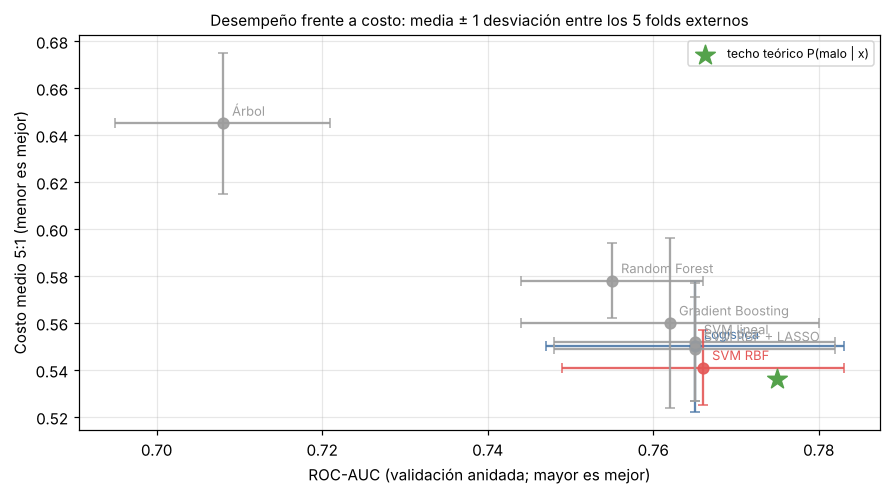

In [3]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
cortos = {"Regresión logística (línea base)": "Logística", "SVM lineal": "SVM lineal", "SVM RBF": "SVM RBF",
          "SVM RBF + selección LASSO": "SVM RBF + LASSO", "Árbol de decisión": "Árbol",
          "Random Forest": "Random Forest", "Gradient Boosting": "Gradient Boosting"}
for n, fila in seleccion.iterrows():
    color = ROJO if n == "SVM RBF" else (AZUL if "logística" in n else GRIS)
    ax.errorbar(fila["ROC-AUC anidada"], fila["Costo medio (5:1) anidada"], xerr=fila["desv. ROC-AUC"],
                yerr=fila["desv. Costo medio (5:1)"], fmt="o", color=color, capsize=3, markersize=7, alpha=0.9)
    ax.annotate(cortos[n], (fila["ROC-AUC anidada"], fila["Costo medio (5:1) anidada"]),
                textcoords="offset points", xytext=(6, 5), fontsize=8.5, color=color)
techo = anidada.loc["Techo teórico: P(malo | x)"]
ax.scatter(*[separar(techo[c])[0] for c in ["ROC-AUC", "Costo medio (5:1)"]], marker="*", s=180,
           color=VERDE, zorder=4, label="techo teórico P(malo | x)")
ax.set_xlabel("ROC-AUC (validación anidada; mayor es mejor)")
ax.set_ylabel("Costo medio 5:1 (menor es mejor)")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3)
ax.set_title("Desempeño frente a costo: media ± 1 desviación entre los 5 folds externos", fontsize=10)
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig1_seleccion.png", bbox_inches="tight")
plt.show()

### ¿Hay diferencia real entre el SVM RBF y la regresión logística?

La validación anidada no encontró diferencia significativa (p = 0.29 en AUC). Lo confirmamos en prueba
con un **bootstrap pareado** (2.000 remuestreos de los mismos 1.300 clientes): si el intervalo de la
diferencia contiene el cero, en esta partición los dos modelos son equivalentes. Ajustamos la logística
con el mismo procedimiento (búsqueda de `C`, umbral de costo mínimo) para que la comparación sea justa.

In [4]:
# Modelo retador: la regresión logística ajustada con el mismo procedimiento
cv_interna = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
logistica = ajustar_modelo(
    construir_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    {"modelo__C": [0.01, 0.1, 1, 10]}, X_train, y_train, cv_interna)

s_svm, s_log = modelo.puntaje(X_test), logistica.puntajes(X_test)
pred_svm, pred_log = modelo.predecir(X_test), logistica.predecir(X_test)

rng = np.random.default_rng(SEED)
B = 2000
boot = []
for _ in range(B):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].sum() in (0, len(i)):
        continue
    boot.append({
        "AUC SVM": roc_auc_score(y_test[i], s_svm[i]),
        "Costo SVM": costo_medio(y_test[i], pred_svm[i]),
        "Recall SVM": pred_svm[i][y_test[i] == 1].mean(),
        "Δ AUC (SVM − log.)": roc_auc_score(y_test[i], s_svm[i]) - roc_auc_score(y_test[i], s_log[i]),
        "Δ costo (SVM − log.)": costo_medio(y_test[i], pred_svm[i]) - costo_medio(y_test[i], pred_log[i]),
    })
boot = pd.DataFrame(boot)
puntual = {"AUC SVM": roc_auc_score(y_test, s_svm), "Costo SVM": costo_medio(y_test, pred_svm),
           "Recall SVM": pred_svm[y_test == 1].mean(),
           "Δ AUC (SVM − log.)": roc_auc_score(y_test, s_svm) - roc_auc_score(y_test, s_log),
           "Δ costo (SVM − log.)": costo_medio(y_test, pred_svm) - costo_medio(y_test, pred_log)}
ic = pd.DataFrame({"valor en test": puntual, "IC 95% inferior": boot.quantile(0.025),
                   "IC 95% superior": boot.quantile(0.975)}).round(4)
print(f"Decisiones idénticas SVM RBF vs. logística en test: {(pred_svm == pred_log).mean():.1%}")
print(f"Correlación de Spearman entre sus puntajes: {spearmanr(s_svm, s_log)[0]:.3f}")
ic

Decisiones idénticas SVM RBF vs. logística en test: 94.2%
Correlación de Spearman entre sus puntajes: 0.985


,valor en test,IC 95% inferior,IC 95% superior
AUC SVM,0.7760,0.7451,0.8043
Costo SVM,0.5362,0.4885,0.5877
Recall SVM,0.8664,0.8270,0.9043
Δ AUC (SVM − log.),0.0023,-0.0036,0.0080
Δ costo (SVM − log.),-0.0031,-0.0308,0.0231


**Decisión.** Elegimos el **SVM con kernel RBF** (`C = 1`, `γ = 0.01`) como modelo final, con la
regresión logística documentada como **modelo retador**. Las razones:

- **Desempeño.** Es el mejor en la regla fijada antes de ver los resultados (mayor ROC-AUC medio; tiene
  también el mejor F1 y el menor costo) y en prueba alcanza el ROC-AUC del techo teórico (0.776). La
  ventaja sobre la logística es pequeña y no significativa: los dos modelos toman la misma decisión en
  el 94% de los clientes y el intervalo bootstrap de la diferencia de AUC contiene el cero. No lo
  elegimos porque sea "mejor", sino porque no es peor en ninguna métrica.
- **Estabilidad.** Tiene la menor desviación de costo entre folds (0.016, empatado con el Random Forest,
  frente a 0.028 de la logística) y eligió los mismos hiperparámetros en 4 de 5 folds externos.
- **Fidelidad al artículo.** Es el método que reproducimos: un modelo que descarta el método del artículo
  tendría que justificarse con una ventaja clara de la alternativa, y no la hay.
- **Interpretabilidad.** Es su punto débil: no tiene coeficientes. Lo compensamos con SHAP a nivel de
  variable original, dependencia parcial y una calibración que traduce el margen a probabilidad. La
  Sección 3 muestra que la explicación resultante es fiel a la estructura verdadera de los datos y que
  el kernel captura la forma en U de la edad, que la logística (lineal en la edad) no puede representar.

El costo de esta elección es operativo: 3.645 vectores de soporte, una explicación SHAP de ~1.5 s por
cliente y la necesidad de documentar la calibración. Si el contexto de uso exigiera reglas auditables
línea por línea (por ejemplo, por una exigencia regulatoria de explicar con coeficientes), la logística
sería una alternativa con el mismo desempeño estadístico.

In [5]:
m_final = pd.DataFrame({
    "SVM RBF (modelo final)": metricas(y_test, s_svm, pred_svm),
    "Regresión logística (retador)": metricas(y_test, s_log, pred_log),
    "Techo teórico P(malo | x)": metricas(y_test, p_test, (p_test >= 1 / 6).astype(int)),
}).T.round(3)
cm = confusion_matrix(y_test, pred_svm)
m_final["Aprobados (%)"] = [(pred_svm == 0).mean(), (pred_log == 0).mean(), (p_test < 1 / 6).mean()]
m_final["Aprobados (%)"] = (100 * m_final["Aprobados (%)"]).round(1)
print("Matriz de confusión del modelo final (filas: real bueno/malo; columnas: predicho bueno/malo):\n", cm)
m_final

Matriz de confusión del modelo final (filas: real bueno/malo; columnas: predicho bueno/malo):
 [[506 502]
 [ 39 253]]


,F1 (malo),ROC-AUC,Recall (malo),Precisión (malo),Costo medio (5:1),Accuracy (ref.),Aprobados (%)
SVM RBF (modelo final),0.483,0.776,0.866,0.335,0.536,0.584,41.9
Regresión logística (retador),0.488,0.774,0.842,0.343,0.539,0.602,44.8
Techo teórico P(malo | x),0.502,0.776,0.836,0.359,0.520,0.628,47.7


## 2. Configuración definitiva y evaluación en prueba

**Configuración.** `Pipeline` del notebook 03 (imputación del saldo por categoría, mediana o moda para
el resto, escalamiento, one-hot) seguido de `SVC(kernel="rbf", C=1, gamma=0.01, class_weight="balanced")`.
El umbral de decisión es el que minimiza el costo 5:1 sobre puntajes fuera de fold de entrenamiento:
−0.492 en el margen del SVM, equivalente a una probabilidad calibrada de 0.142. El conjunto de prueba se
usa aquí por última vez, con exactamente el mismo modelo que se despliega.

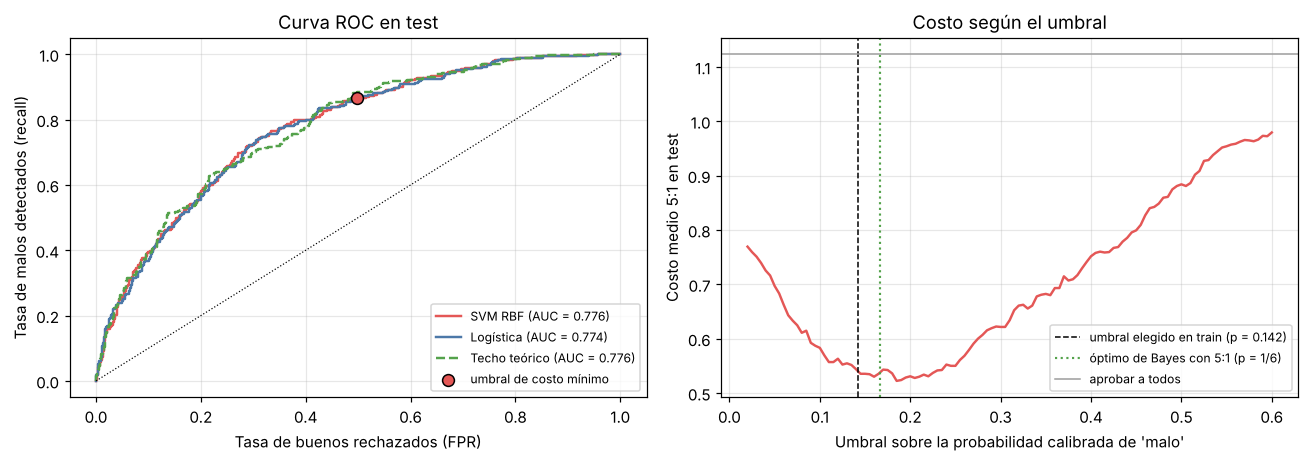

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for s, nombre, color in [(s_svm, "SVM RBF", ROJO), (s_log, "Logística", AZUL), (p_test, "Techo teórico", VERDE)]:
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=color, lw=1.6, label=f"{nombre} (AUC = {roc_auc_score(y_test, s):.3f})",
                 linestyle="--" if nombre == "Techo teórico" else "-")
axes[0].plot([0, 1], [0, 1], color="black", lw=0.8, linestyle=":")
fpr_u = (pred_svm[y_test == 0]).mean()
tpr_u = (pred_svm[y_test == 1]).mean()
axes[0].scatter([fpr_u], [tpr_u], color=ROJO, s=60, zorder=4, edgecolor="black", label="umbral de costo mínimo")
axes[0].set_xlabel("Tasa de buenos rechazados (FPR)")
axes[0].set_ylabel("Tasa de malos detectados (recall)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Curva ROC en test")
axes[0].grid(alpha=0.3)

umbrales_p = np.linspace(0.02, 0.6, 117)
prob_test = modelo.probabilidad(puntaje=s_svm)
costos_u = [costo_medio(y_test, (prob_test >= u).astype(int)) for u in umbrales_p]
axes[1].plot(umbrales_p, costos_u, color=ROJO, lw=1.6)
axes[1].axvline(modelo.umbral_probabilidad, color="black", linestyle="--", lw=1,
                label=f"umbral elegido en train (p = {modelo.umbral_probabilidad:.3f})")
axes[1].axvline(1 / 6, color=VERDE, linestyle=":", lw=1.4, label="óptimo de Bayes con 5:1 (p = 1/6)")
axes[1].axhline(costo_medio(y_test, np.zeros_like(y_test)), color=GRIS, lw=1, label="aprobar a todos")
axes[1].set_xlabel("Umbral sobre la probabilidad calibrada de 'malo'")
axes[1].set_ylabel("Costo medio 5:1 en test")
axes[1].legend(fontsize=8)
axes[1].set_title("Costo según el umbral")
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig2_roc_costo.png", bbox_inches="tight")
plt.show()

La curva ROC del SVM es prácticamente indistinguible de la del techo teórico. El panel derecho muestra
por qué el umbral está tan abajo (0.142 y no 0.5): con un falso negativo 5 veces más caro, conviene
rechazar desde un riesgo cercano a 1/(1+5) = 0.167. El costo es casi plano entre 0.13 y 0.23, así que el
umbral elegido en entrenamiento está en una zona robusta.

### Calibración

El SVM no produce probabilidades. Para mostrarlas en la aplicación ajustamos una **calibración de Platt**
(una regresión logística sobre el margen) con los mismos puntajes fuera de fold del umbral. Es monótona,
así que no cambia ni el ROC-AUC ni las decisiones.

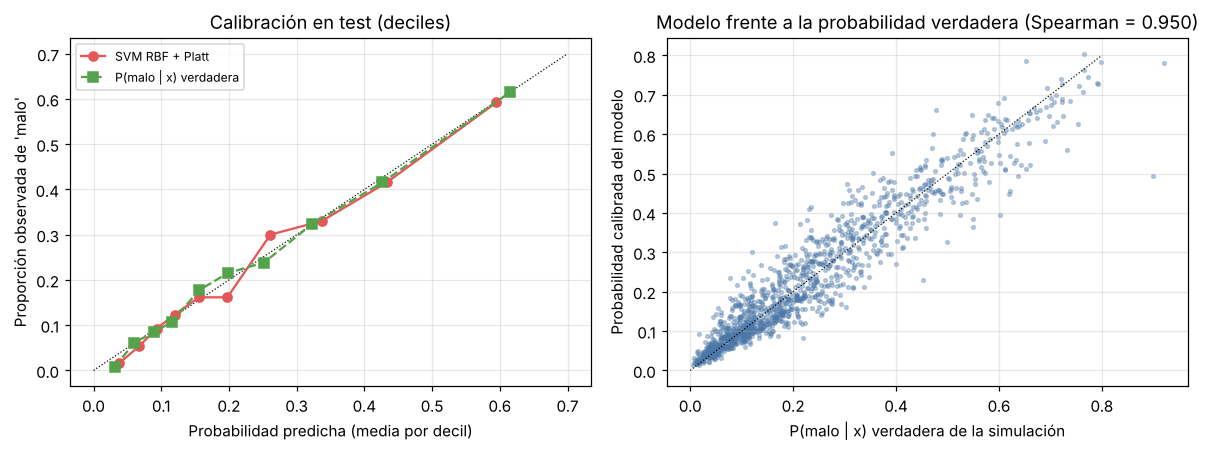

Brier del modelo: 0.1440 | Brier de la probabilidad verdadera: 0.1435 | Error de calibración esperado (ECE, deciles): 0.015
Probabilidad media predicha: 0.230 | tasa observada de 'malo': 0.225
Error absoluto medio frente a P verdadera: 0.038


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
frac, media_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
axes[0].plot([0, 0.7], [0, 0.7], color="black", lw=0.8, linestyle=":")
axes[0].plot(media_pred, frac, marker="o", color=ROJO, label="SVM RBF + Platt")
frac_t, media_t = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[0].plot(media_t, frac_t, marker="s", color=VERDE, linestyle="--", label="P(malo | x) verdadera")
axes[0].set_xlabel("Probabilidad predicha (media por decil)")
axes[0].set_ylabel("Proporción observada de 'malo'")
axes[0].set_title("Calibración en test (deciles)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].scatter(p_test, prob_test, s=6, alpha=0.35, color=AZUL)
axes[1].plot([0, 0.8], [0, 0.8], color="black", lw=0.8, linestyle=":")
axes[1].set_xlabel("P(malo | x) verdadera de la simulación")
axes[1].set_ylabel("Probabilidad calibrada del modelo")
axes[1].set_title(f"Modelo frente a la probabilidad verdadera (Spearman = {spearmanr(p_test, prob_test)[0]:.3f})")
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig3_calibracion.png", bbox_inches="tight")
plt.show()

ece = np.average(np.abs(frac - media_pred), weights=np.histogram(prob_test, np.quantile(prob_test, np.linspace(0, 1, 11)))[0])
print(f"Brier del modelo: {brier_score_loss(y_test, prob_test):.4f} | Brier de la probabilidad verdadera: "
      f"{brier_score_loss(y_test, p_test):.4f} | Error de calibración esperado (ECE, deciles): {ece:.3f}")
print(f"Probabilidad media predicha: {prob_test.mean():.3f} | tasa observada de 'malo': {y_test.mean():.3f}")
print(f"Error absoluto medio frente a P verdadera: {np.abs(prob_test - p_test).mean():.3f}")

La calibración es muy buena: los deciles caen sobre la diagonal (error de calibración de 0.015), la
probabilidad media predicha (23.0%) coincide con la tasa observada (22.5%) y el Brier score (0.1440) es
prácticamente el de la probabilidad verdadera (0.1435). Frente a la probabilidad verdadera de cada
cliente, el error absoluto medio es de 3.8 puntos porcentuales. Que una calibración de un solo parámetro
funcione tan bien es coherente con una estructura de riesgo casi lineal en el logit.

## 3. Interpretación con SHAP

Calculamos los valores SHAP con el algoritmo de permutación sobre la **función completa** (pipeline +
SVM), tratando cada una de las 11 variables del formulario como una unidad: así la explicación habla de
"historial de pago" y no de 4 columnas one-hot. El valor explicado es el margen del SVM; la suma del
valor base y los SHAP de un cliente reproduce exactamente su puntaje (aditividad). Usamos 400 clientes
de prueba y un fondo de 50 clientes de entrenamiento.

In [8]:
# SHAP: 400 clientes de test, fondo de 50 clientes de entrenamiento. Se reparte en 2 procesos.
N_SHAP, N_FONDO = 400, 50
muestra = X_test.sample(N_SHAP, random_state=SEED)
fondo = artefacto["fondo_shap"].iloc[:N_FONDO]

def explicar_lote(lote):
    return crear_explicador(modelo, fondo)(lote)

t0 = time.time()
lotes = np.array_split(np.arange(N_SHAP), 4)
partes = Parallel(n_jobs=2)(delayed(explicar_lote)(muestra.iloc[i]) for i in lotes)
shap_vals = np.vstack([p.values for p in partes])
base_shap = float(partes[0].base_values[0])
print(f"SHAP de {N_SHAP} clientes en {time.time() - t0:.0f} s")
print("Aditividad (máx. |base + Σ SHAP − puntaje|):",
      np.abs(base_shap + shap_vals.sum(1) - modelo.puntaje(muestra)).max().round(8))
shap_df = pd.DataFrame(shap_vals, columns=COLUMNAS, index=muestra.index)
shap_df.to_csv(DIR_RES / "06_valores_shap_test.csv")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP de 400 clientes en 348 s
Aditividad (máx. |base + Σ SHAP − puntaje|): 0.0


### SHAP frente a la estructura verdadera

Como la base es simulada, conocemos la contribución verdadera de cada variable al logit del riesgo. Para
un puntaje aditivo, su valor SHAP verdadero es esa contribución menos su media en el fondo. Llevamos el
SHAP del SVM a escala logit con la pendiente de Platt para poder comparar magnitudes.

In [9]:
def componentes_verdaderos(idx, ref):
    """Contribución de cada variable al puntaje latente de la simulación (escala logit)."""
    df, comp = base_completa, pd.DataFrame(index=idx)
    for c in ["saldo_categoria", "nivel_ahorro", "estado_pago_previo", "proposito_credito",
              "tipo_ocupacion", "tipo_vivienda"]:
        comp[c] = df.loc[idx, c].map(PESOS_CATEGORICOS[c]).to_numpy()
    lm = np.log(df["monto_credito_cop"])
    comp["monto_credito_cop"] = PESOS_NUMERICOS["log_monto"] * ((lm - lm.mean()) / lm.std()).loc[idx].to_numpy()
    pz = df["plazo_meses"]
    comp["plazo_meses"] = PESOS_NUMERICOS["plazo"] * ((pz - pz.mean()) / pz.std()).loc[idx].to_numpy()
    e = (df["edad"] - df["edad"].mean()) / df["edad"].std()
    comp["edad"] = (PESOS_NUMERICOS["edad_cuadrado"] * e**2 + PESOS_NUMERICOS["edad"] * e).loc[idx].to_numpy()
    comp["genero"] = 0.0
    comp["saldo_cuenta_cop"] = 0.0
    return comp[COLUMNAS]

# SHAP verdadero: para un puntaje aditivo, contribución menos su media en el mismo fondo
comp_fondo = componentes_verdaderos(fondo.index, None)
shap_verdadero = componentes_verdaderos(muestra.index, None) - comp_fondo.mean()

# Para comparar escalas, el margen del SVM se lleva a logit con la calibración de Platt (a · SHAP)
shap_logit = artefacto["calibrador"][0] * shap_df
importancia = pd.DataFrame({
    "SVM RBF: media |SHAP| (logit)": shap_logit.abs().mean(),
    "Simulación: media |contribución| (logit)": shap_verdadero.abs().mean(),
})
importancia["% del total (SVM)"] = 100 * importancia.iloc[:, 0] / importancia.iloc[:, 0].sum()
importancia["% del total (simulación)"] = 100 * importancia.iloc[:, 1] / importancia.iloc[:, 1].sum()
importancia["correlación por cliente"] = [
    np.corrcoef(shap_df[c], shap_verdadero[c])[0, 1] if shap_verdadero[c].std() > 0 else np.nan for c in COLUMNAS]
importancia.index = [NOMBRES[c] for c in importancia.index]
importancia = importancia.sort_values("% del total (SVM)", ascending=False)
print(f"Spearman entre rankings (SVM vs. simulación): "
      f"{spearmanr(importancia.iloc[:, 0], importancia.iloc[:, 1])[0]:.3f}")
cuenta = ["Categoría de saldo", "Saldo en cuenta (COP)"]
print(f"Bloque 'cuenta bancaria' (categoría + saldo): SVM {importancia.loc[cuenta, '% del total (SVM)'].sum():.1f}% "
      f"| simulación {importancia.loc[cuenta, '% del total (simulación)'].sum():.1f}%")
grupo_c = shap_df["saldo_categoria"] + shap_df["saldo_cuenta_cop"]
print(f"Correlación por cliente del bloque cuenta: {np.corrcoef(grupo_c, shap_verdadero['saldo_categoria'])[0, 1]:.3f}")
importancia.to_csv(DIR_RES / "06_tabla_importancia_shap.csv")
importancia.round(3)

Spearman entre rankings (SVM vs. simulación): 0.884
Bloque 'cuenta bancaria' (categoría + saldo): SVM 17.6% | simulación 16.4%
Correlación por cliente del bloque cuenta: 0.955


,SVM RBF: media |SHAP| (logit),Simulación: media |contribución| (logit),% del total (SVM),% del total (simulación),correlación por cliente
Historial de pago,0.658,0.626,28.624,22.380,0.986
Categoría de saldo,0.304,0.458,13.223,16.361,0.944
Plazo (meses),0.287,0.255,12.464,9.107,0.981
Tipo de vivienda,0.218,0.247,9.457,8.841,0.998
Tipo de ocupación,0.216,0.309,9.405,11.050,0.882
Monto del crédito (COP),0.167,0.351,7.275,12.563,0.943
Nivel de ahorro,0.136,0.236,5.913,8.449,0.945
Propósito del crédito,0.110,0.147,4.800,5.269,0.857
Saldo en cuenta (COP),0.100,0.000,4.335,0.000,NaN
Edad,0.094,0.167,4.091,5.979,0.721


**Lectura.** El orden de importancia del SVM coincide con el de la simulación (Spearman 0.88) y, cliente
por cliente, sus contribuciones se correlacionan con las verdaderas por encima de 0.94 en las seis
variables más importantes. El historial de pago es la variable dominante (29% de la importancia), seguida
de la cuenta bancaria, el plazo, la vivienda y la ocupación.

Hay dos diferencias que no son errores del modelo sino propiedades de SHAP con variables correlacionadas:

- **Cuenta bancaria.** En la simulación solo importa la categoría de saldo; el SVM reparte ese efecto entre
  la categoría y el saldo en COP, que están correlacionados. Sumadas, pesan 17.6% frente a 16.4%
  verdadero, y la correlación por cliente del bloque es 0.955.
- **Plazo y monto.** El modelo atribuye más al plazo y menos al monto que la simulación (el monto se
  generó como función del plazo, correlación 0.60).

El **género** tiene contribución prácticamente nula (0.4% de la importancia, media |SHAP| de 0.009), lo
cual es correcto: no interviene en el riesgo simulado.

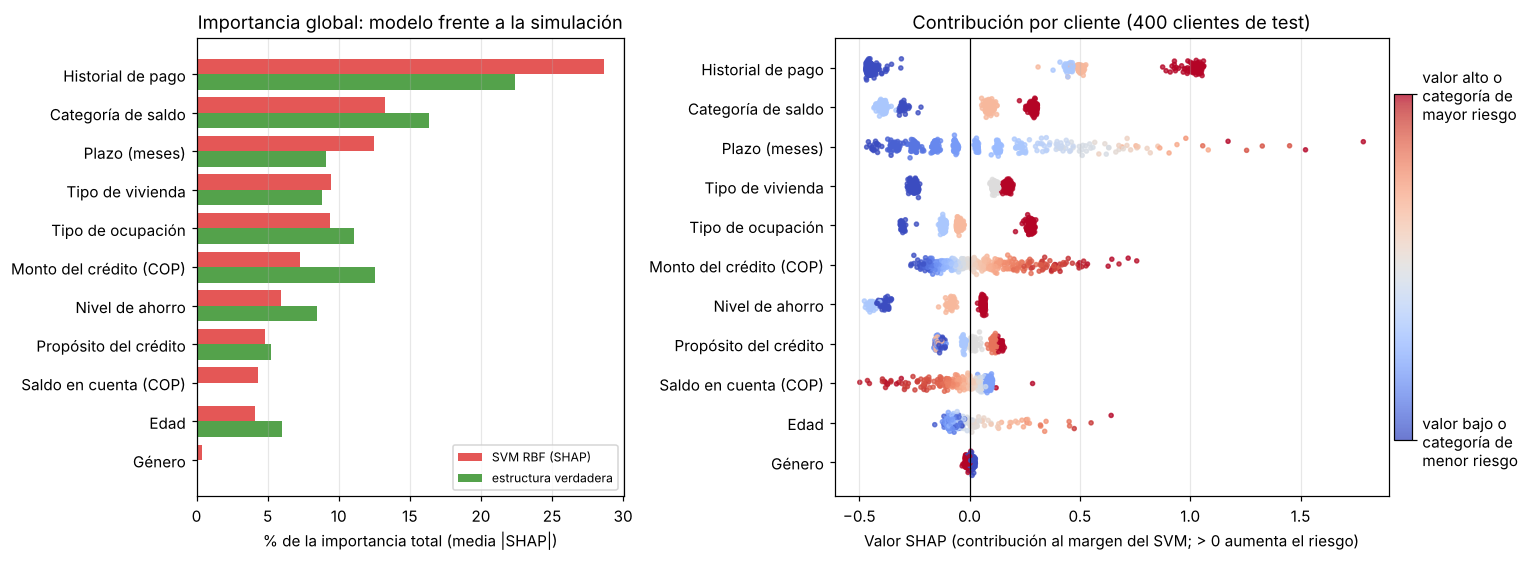

In [10]:
import shap

orden = shap_df.abs().mean().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.35]})
y = np.arange(len(orden))
axes[0].barh(y + 0.2, importancia.loc[[NOMBRES[c] for c in orden], "% del total (SVM)"], height=0.4,
             color=ROJO, label="SVM RBF (SHAP)")
axes[0].barh(y - 0.2, importancia.loc[[NOMBRES[c] for c in orden], "% del total (simulación)"], height=0.4,
             color=VERDE, label="estructura verdadera")
axes[0].set_yticks(y)
axes[0].set_yticklabels([NOMBRES[c] for c in orden])
axes[0].set_xlabel("% de la importancia total (media |SHAP|)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Importancia global: modelo frente a la simulación")
axes[0].grid(alpha=0.3, axis="x")

# Diagrama de enjambre: cada punto es un cliente; color = valor de la variable (rango dentro de la variable)
cod = Codificador(artefacto["perfil"]["categorias"])
M = cod.codificar(muestra)
for k, c in enumerate(orden):
    j = COLUMNAS.index(c)
    v = shap_df[c].to_numpy()
    col = M[:, j]
    rango = (col - np.nanmin(col)) / max(np.nanmax(col) - np.nanmin(col), 1e-9)
    if c == "monto_credito_cop" or c == "saldo_cuenta_cop":
        r = pd.Series(col).rank(pct=True).to_numpy()
        rango = r
    jitter = np.random.default_rng(k).normal(0, 0.09, len(v))
    sc = axes[1].scatter(v, k + jitter, c=rango, cmap="coolwarm", s=7, alpha=0.75, vmin=0, vmax=1)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_yticks(range(len(orden)))
axes[1].set_yticklabels([NOMBRES[c] for c in orden])
axes[1].set_xlabel("Valor SHAP (contribución al margen del SVM; > 0 aumenta el riesgo)")
axes[1].set_title(f"Contribución por cliente ({N_SHAP} clientes de test)")
cb = fig.colorbar(sc, ax=axes[1], fraction=0.03, pad=0.01)
cb.set_ticks([0, 1])
cb.set_ticklabels(["valor bajo o\ncategoría de\nmenor riesgo", "valor alto o\ncategoría de\nmayor riesgo"])
axes[1].grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig4_shap_global.png", bbox_inches="tight")
plt.show()

### Efecto por categoría

Promediamos el SHAP de los clientes de cada categoría y lo comparamos con la contribución verdadera. La
correlación es 0.92 y el orden de las categorías se respeta en el historial de pago, la ocupación, la
vivienda y la cuenta. La discrepancia más relevante es **"sin créditos previos"**: el modelo le asigna
casi el mismo riesgo que a la mora leve (+0.50 frente a +0.16 verdadero). Es un efecto del muestreo (solo
9% de los clientes) que tiene una consecuencia práctica, porque penaliza el historial delgado, típico de
quien pide su primer crédito.

In [11]:
# Efecto medio de cada categoría según SHAP, frente al peso verdadero (ambos centrados)
filas = []
for c in ["estado_pago_previo", "saldo_categoria", "tipo_ocupacion", "nivel_ahorro", "tipo_vivienda",
          "proposito_credito"]:
    for cat in artefacto["perfil"]["categorias"][c]:
        m = muestra[c] == cat
        if m.sum() < 5:
            continue
        filas.append({"variable": NOMBRES[c], "categoría": cat, "clientes": int(m.sum()),
                      "SHAP medio (logit)": shap_logit.loc[m, c].mean(),
                      "contribución verdadera (logit)": shap_verdadero.loc[m, c].mean()})
efectos_cat = pd.DataFrame(filas)
print(f"Correlación entre efectos por categoría (modelo vs. verdad): "
      f"{np.corrcoef(efectos_cat.iloc[:, 3], efectos_cat.iloc[:, 4])[0, 1]:.3f}")
efectos_cat.round(3)

Correlación entre efectos por categoría (modelo vs. verdad): 0.920


,variable,categoría,clientes,SHAP medio (logit),contribución verdadera (logit)
0,Historial de pago,al_dia,225,-0.501,-0.490
1,Historial de pago,sin_creditos_previos,43,0.503,0.160
2,Historial de pago,mora_leve,36,0.554,0.610
3,Historial de pago,mora_severa,96,1.136,1.160
4,Categoría de saldo,alto,32,-0.332,-0.986
5,Categoría de saldo,medio,115,-0.441,-0.536
6,Categoría de saldo,bajo,96,0.099,0.014
7,Categoría de saldo,sin_cuenta,157,0.324,0.564
8,Tipo de ocupación,alta_calificacion,35,-0.338,-0.579
9,Tipo de ocupación,formal_calificado,103,-0.135,-0.229


## 4. Dependencia parcial e ICE

La dependencia parcial (PDP) promedia el efecto de fijar una variable en cada valor de la grilla sobre
600 clientes de entrenamiento; las curvas ICE muestran ese efecto cliente por cliente. Las tres curvas
están en escala logit y centradas: el SVM (con la pendiente de Platt), la regresión logística y la
estructura verdadera (atenuada por el ruido latente, factor κ ≈ 0.88).

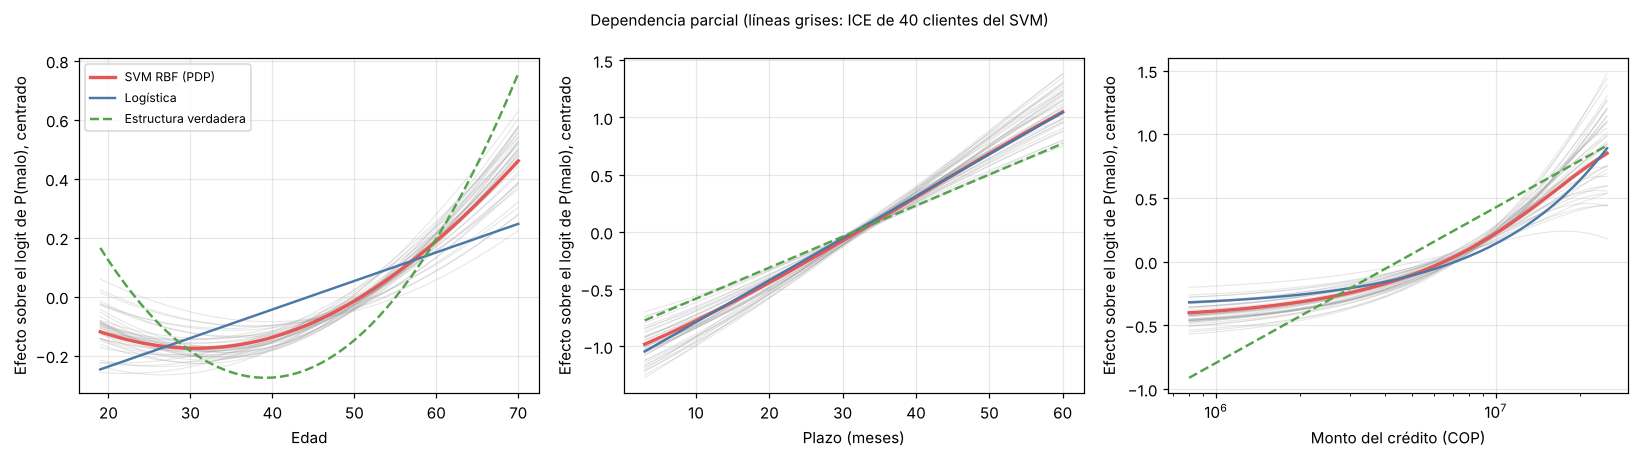

Edad - SVM: mínimo en 31 años; efecto a los 19 = -0.119, a los 70 = +0.461
Edad - logística: mínimo en 19 años; efecto a los 19 = -0.247, a los 70 = +0.247
Edad - verdad: mínimo en 39 años; efecto a los 19 = +0.165, a los 70 = +0.757


In [12]:
# Dependencia parcial (PDP) e ICE calculadas a mano sobre el pipeline completo
pdp_base = X_train.sample(600, random_state=SEED)
kappa = 1 / np.sqrt(1 + np.pi * SD_RUIDO_LATENTE**2 / 8)   # atenuación del logit al integrar el ruido latente
a_platt, b_platt = artefacto["calibrador"]

def pdp(estimador_logit, col, grilla, base=pdp_base):
    curvas = []
    for v in grilla:
        Xv = base.copy()
        Xv[col] = v
        curvas.append(estimador_logit(Xv))
    return np.array(curvas)            # (grilla, clientes)

logit_svm = lambda X: a_platt * modelo.puntaje(X) + b_platt     # noqa: E731
logit_log_p = lambda X: np.log(logistica.estimador.predict_proba(X)[:, 1] / logistica.estimador.predict_proba(X)[:, 0])  # noqa: E731

def verdad_numerica(col, grilla):
    df = base_completa
    if col == "edad":
        e = (grilla - df["edad"].mean()) / df["edad"].std()
        return PESOS_NUMERICOS["edad_cuadrado"] * e**2 + PESOS_NUMERICOS["edad"] * e
    if col == "plazo_meses":
        return PESOS_NUMERICOS["plazo"] * (grilla - df["plazo_meses"].mean()) / df["plazo_meses"].std()
    lm = np.log(df["monto_credito_cop"])
    return PESOS_NUMERICOS["log_monto"] * (np.log(grilla) - lm.mean()) / lm.std()

grillas = {"edad": np.arange(19, 71, 1.0), "plazo_meses": np.arange(3, 61, 3.0),
           "monto_credito_cop": np.geomspace(800_000, 25_000_000, 40)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
pdp_resultados = {}
for ax, (col, g) in zip(axes, grillas.items()):
    ice = pdp(logit_svm, col, g)
    curva_svm = ice.mean(axis=1)
    curva_log = pdp(logit_log_p, col, g).mean(axis=1)
    verdad = kappa * verdad_numerica(col, g)
    centro = lambda v: v - v.mean()    # noqa: E731
    for i in np.random.default_rng(SEED).choice(ice.shape[1], 40, replace=False):
        ax.plot(g, centro(ice[:, i]), color=GRIS, alpha=0.25, lw=0.7)
    ax.plot(g, centro(curva_svm), color=ROJO, lw=2.2, label="SVM RBF (PDP)")
    ax.plot(g, centro(curva_log), color=AZUL, lw=1.6, label="Logística")
    ax.plot(g, centro(verdad), color=VERDE, lw=1.6, linestyle="--", label="Estructura verdadera")
    pdp_resultados[col] = pd.DataFrame({"valor": g, "SVM": centro(curva_svm), "logística": centro(curva_log),
                                        "verdad": centro(verdad)})
    ax.set_xlabel(NOMBRES[col])
    if col == "monto_credito_cop":
        ax.set_xscale("log")
    ax.set_ylabel("Efecto sobre el logit de P(malo), centrado")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Dependencia parcial (líneas grises: ICE de 40 clientes del SVM)", fontsize=10)
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig5_dependencia_parcial.png", bbox_inches="tight")
plt.show()

e = pdp_resultados["edad"]
for nombre in ["SVM", "logística", "verdad"]:
    print(f"Edad - {nombre}: mínimo en {e.loc[e[nombre].idxmin(), 'valor']:.0f} años; "
          f"efecto a los 19 = {e[nombre].iloc[0]:+.3f}, a los 70 = {e[nombre].iloc[-1]:+.3f}")

**Lectura.**

- **Edad.** Es la única no linealidad de la simulación (forma en U con mínimo hacia los 39 años). El SVM
  la recupera parcialmente (mínimo hacia los 31 años y riesgo creciente después de los 50); la
  logística, lineal en la edad, solo puede trazar una recta. Es el único lugar donde el kernel RBF
  aporta algo que un modelo lineal no puede representar, y explica parte de su pequeña ventaja.
- **Plazo.** Efecto lineal y creciente en los tres. Las curvas ICE son casi paralelas: el efecto del
  plazo no depende de las demás características (no hay interacciones relevantes).
- **Monto.** Creciente, pero el SVM y la logística son más planos que la verdad en montos bajos: parte
  del efecto del monto lo absorbe el plazo, con el que está correlacionado.

## 5. Explicaciones individuales: SHAP frente a LIME

Elegimos tres clientes de prueba sin faltantes: un malo detectado, un malo aprobado (el error más caro) y
un bueno rechazado. LIME ajusta un modelo lineal local alrededor de cada cliente sobre la probabilidad
calibrada; SHAP reparte el margen del SVM. Si las dos técnicas, con supuestos distintos, señalan las
mismas variables, la explicación es más confiable.

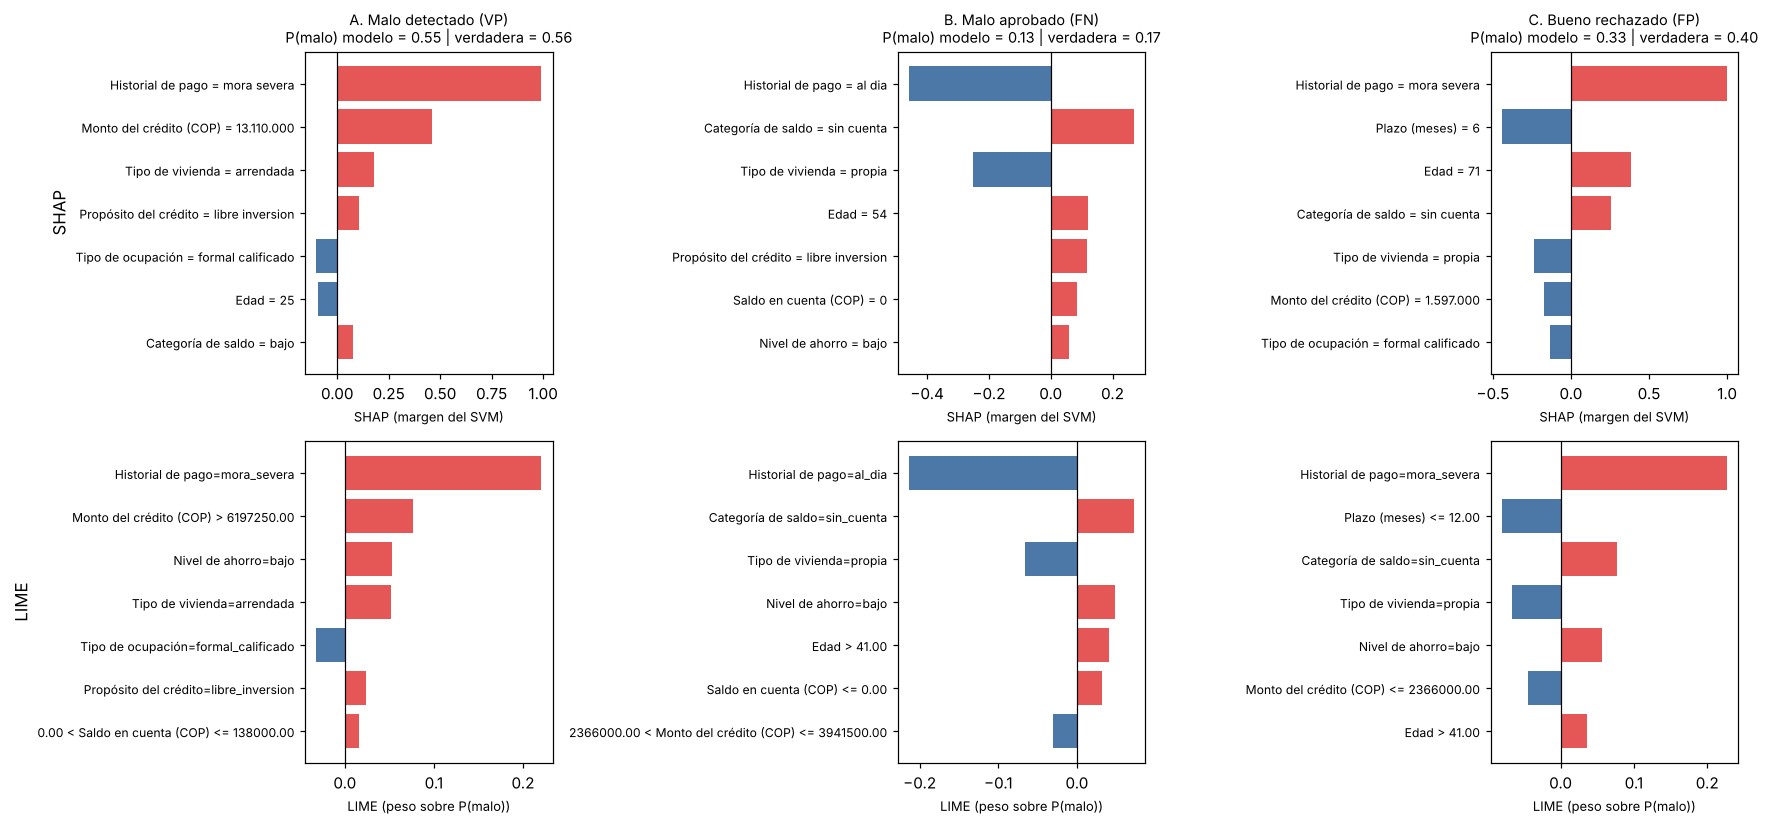

                                 1665                  6196               2363
edad                             25.0                  54.0               71.0
genero                              M                     F                  F
tipo_ocupacion      formal_calificado  formal_no_calificado  formal_calificado
tipo_vivienda               arrendada                propia             propia
nivel_ahorro                     bajo                  bajo               bajo
saldo_categoria                  bajo            sin_cuenta         sin_cuenta
saldo_cuenta_cop              94000.0                   0.0                0.0
monto_credito_cop          13110000.0             3702000.0          1597000.0
plazo_meses                      21.0                  21.0                6.0
proposito_credito     libre_inversion       libre_inversion    libre_inversion
estado_pago_previo        mora_severa                al_dia        mora_severa


,caso,P(malo) modelo,P(malo) verdadera,top-3 SHAP,top-3 LIME,coincidencias en el top-3
0,A. Malo detectado (VP),0.552,0.558,"Historial de pago, Monto del crédito (COP), Ti...","Historial de pago, Monto del crédito (COP), Ni...",2
1,B. Malo aprobado (FN),0.135,0.168,"Historial de pago, Categoría de saldo, Tipo de...","Historial de pago, Categoría de saldo, Tipo de...",3
2,C. Bueno rechazado (FP),0.328,0.403,"Historial de pago, Plazo (meses), Edad","Historial de pago, Plazo (meses), Categoría de...",2


In [13]:
# LIME frente a SHAP en tres casos de test: un malo detectado, un malo aprobado y un bueno rechazado
from lime.lime_tabular import LimeTabularExplainer

det = X_test.copy()
det["real"], det["pred"], det["prob"], det["p_teorica"] = y_test, pred_svm, prob_test, p_test
casos = {
    "A. Malo detectado (VP)": det[(det.real == 1) & (det.pred == 1) & det[COLUMNAS].notna().all(axis=1)].sort_values("prob").index[-40],
    "B. Malo aprobado (FN)": det[(det.real == 1) & (det.pred == 0) & det[COLUMNAS].notna().all(axis=1)].sort_values("prob").index[-3],
    "C. Bueno rechazado (FP)": det[(det.real == 0) & (det.pred == 1) & det[COLUMNAS].notna().all(axis=1)].sort_values("prob").index[len(det[(det.real == 0) & (det.pred == 1)]) // 2],
}
X_casos = X_test.loc[list(casos.values())]
exp_casos = crear_explicador(modelo, fondo)(X_casos)

entreno_lime = X_train.copy()
for c in NUM_COLS:
    entreno_lime[c] = entreno_lime[c].fillna(entreno_lime[c].median())
for c in CAT_COLS:
    entreno_lime[c] = entreno_lime[c].fillna(entreno_lime[c].mode()[0])
M_lime = cod.codificar(entreno_lime)
idx_cat = [COLUMNAS.index(c) for c in CAT_COLS]
lime_exp = LimeTabularExplainer(
    M_lime, feature_names=[NOMBRES[c] for c in COLUMNAS], class_names=["bueno", "malo"],
    categorical_features=idx_cat,
    categorical_names={COLUMNAS.index(c): artefacto["perfil"]["categorias"][c] for c in CAT_COLS},
    discretize_continuous=True, random_state=SEED)
proba_fn = lambda M: np.column_stack([1 - modelo.probabilidad(cod.decodificar(M)), modelo.probabilidad(cod.decodificar(M))])  # noqa: E731

fig, axes = plt.subplots(2, 3, figsize=(16, 7.6))
resumen_casos = []
for k, (titulo, idx) in enumerate(casos.items()):
    fila = X_test.loc[idx]
    t = tabla_explicacion(exp_casos[k], fila).head(7).iloc[::-1]
    axes[0, k].barh([f"{v} = {x}" for v, x in zip(t["Variable"], t["Valor"])], t["Contribución"],
                    color=[ROJO if v > 0 else AZUL for v in t["Contribución"]])
    axes[0, k].axvline(0, color="black", lw=0.8)
    axes[0, k].set_title(f"{titulo}\nP(malo) modelo = {det.loc[idx, 'prob']:.2f} | verdadera = {det.loc[idx, 'p_teorica']:.2f}",
                         fontsize=9.5)
    axes[0, k].tick_params(axis="y", labelsize=8)
    axes[0, k].set_xlabel("SHAP (margen del SVM)", fontsize=8.5)
    le = lime_exp.explain_instance(cod.codificar(fila.to_frame().T)[0], proba_fn, num_features=7,
                                   num_samples=3000)
    pares = le.as_list()[::-1]
    axes[1, k].barh([p[0] for p in pares], [p[1] for p in pares],
                    color=[ROJO if p[1] > 0 else AZUL for p in pares])
    axes[1, k].axvline(0, color="black", lw=0.8)
    axes[1, k].tick_params(axis="y", labelsize=8)
    axes[1, k].set_xlabel("LIME (peso sobre P(malo))", fontsize=8.5)
    top_shap = list(tabla_explicacion(exp_casos[k], fila)["Variable"].head(3))
    top_lime = [next(NOMBRES[c] for c in COLUMNAS if NOMBRES[c] in p[0]) for p in le.as_list()[:3]]
    resumen_casos.append({"caso": titulo, "P(malo) modelo": round(det.loc[idx, "prob"], 3),
                          "P(malo) verdadera": round(det.loc[idx, "p_teorica"], 3),
                          "top-3 SHAP": ", ".join(top_shap), "top-3 LIME": ", ".join(top_lime),
                          "coincidencias en el top-3": len(set(top_shap) & set(top_lime))})
axes[0, 0].set_ylabel("SHAP", fontsize=11)
axes[1, 0].set_ylabel("LIME", fontsize=11)
fig.tight_layout()
fig.savefig(DIR_RES / "06_fig6_casos_shap_lime.png", bbox_inches="tight")
plt.show()
print(X_casos.T)
pd.DataFrame(resumen_casos)

**Lectura.** SHAP y LIME coinciden en la variable principal de los tres casos y en 7 de las 9
variables del top-3. Los tres casos ilustran los tipos de error:

- **A (malo detectado).** Mora severa y un monto alto (13.1 millones) explican el rechazo.
- **B (malo aprobado).** Historial al día y vivienda propia pesan más que no tener cuenta. Su
  probabilidad verdadera es 0.17, casi en el umbral: es un error difícil de evitar con estas variables.
- **C (bueno rechazado).** La mora severa domina aunque el plazo sea corto. Su probabilidad verdadera es
  0.40: el modelo acertó al considerarlo riesgoso; que pagara es parte del ruido irreducible.

LIME es menos estable (depende del muestreo aleatorio y de la discretización de las numéricas), así que
la aplicación usa SHAP.

## 6. Tipos de error e implicaciones

In [14]:
# Tipos de error y su costo en test
tn, fp, fn, tp = cm.ravel()
errores = pd.DataFrame({
    "clientes": [tp, fn, fp, tn],
    "costo unitario": [0, 5, 1, 0],
}, index=["Malo detectado (VP)", "Malo aprobado (FN)", "Bueno rechazado (FP)", "Bueno aprobado (VN)"])
errores["costo total"] = errores["clientes"] * errores["costo unitario"]
errores["% del costo"] = (100 * errores["costo total"] / errores["costo total"].sum()).round(1)
print(f"Costo medio por cliente: {errores['costo total'].sum() / len(y_test):.3f} "
      f"| aprobar a todos costaría {costo_medio(y_test, np.zeros_like(y_test)):.3f} "
      f"| rechazar a todos costaría {costo_medio(y_test, np.ones_like(y_test)):.3f}")
errores

Costo medio por cliente: 0.536 | aprobar a todos costaría 1.123 | rechazar a todos costaría 0.775


,clientes,costo unitario,costo total,% del costo
Malo detectado (VP),253,0,0,0.0
Malo aprobado (FN),39,5,195,28.0
Bueno rechazado (FP),502,1,502,72.0
Bueno aprobado (VN),506,0,0,0.0


Los falsos positivos (buenos rechazados) aportan el 72% del costo; los falsos negativos, el 28%. El
modelo cuesta 0.536 por cliente, frente a 1.123 de aprobar a todos y 0.775 de rechazar a todos.

### Equidad por género

In [15]:
# Equidad: el género no entra en la estructura verdadera; ¿lo usa el modelo?
def por_grupo(col):
    g = det.groupby(col, observed=True)
    return pd.DataFrame({
        "clientes": g.size(),
        "% malo real": 100 * g["real"].mean(),
        "% aprobados": 100 * (1 - g["pred"].mean()),
        "recall (malo)": g.apply(lambda d: d.loc[d.real == 1, "pred"].mean(), include_groups=False),
        "% de buenos rechazados": 100 * g.apply(lambda d: d.loc[d.real == 0, "pred"].mean(), include_groups=False),
        "P(malo) media del modelo": g["prob"].mean(),
    }).round(3)

print("Contribución SHAP media del género (margen):",
      shap_df.groupby(muestra["genero"])["genero"].mean().round(4).to_dict(),
      "| media |SHAP| del género:", round(shap_df["genero"].abs().mean(), 4))
eq_genero = por_grupo("genero")
eq_genero

Contribución SHAP media del género (margen): {'F': 0.0069, 'M': -0.0064} | media |SHAP| del género: 0.0085


,clientes,% malo real,% aprobados,recall (malo),% de buenos rechazados,P(malo) media del modelo
genero,,,,,,
F,623,21.509,39.326,0.873,53.374,0.231
M,677,23.338,44.313,0.861,46.435,0.229


El modelo no usa el género (contribución media de ±0.007 en el margen) y la probabilidad media predicha
es la misma para ambos grupos (0.231 frente a 0.229), en línea con su tasa real de malos. El recall es
similar (0.87 frente a 0.86). La tasa de rechazo de buenas clientes es algo mayor en mujeres (53% frente
a 46%) por la composición de las demás variables en esta muestra de prueba, no por el género: es una
diferencia que una entidad debería monitorear. En un despliegue real convendría **retirar el género**
del modelo.

### Efecto por segmento

In [16]:
for col in ["saldo_categoria", "tipo_ocupacion", "estado_pago_previo"]:
    print(f"\n=== {NOMBRES[col]} ===")
    print(por_grupo(col).reindex(artefacto["perfil"]["categorias"][col]).to_string())


=== Categoría de saldo ===
                 clientes  % malo real  % aprobados  recall (malo)  % de buenos rechazados  P(malo) media del modelo
saldo_categoria                                                                                                     
alto                   82        2.439       67.073          0.500                  32.500                     0.123
medio                 329       14.590       58.967          0.708                  35.943                     0.150
bajo                  378       21.693       37.831          0.915                  54.054                     0.241
sin_cuenta            511       31.311       29.941          0.894                  61.254                     0.290

=== Tipo de ocupación ===
                      clientes  % malo real  % aprobados  recall (malo)  % de buenos rechazados  P(malo) media del modelo
tipo_ocupacion                                                                                                           

La política castiga con fuerza a los segmentos de mayor riesgo: aprueba al 69% de los clientes al día,
pero solo al 22% de quienes no tienen créditos previos y al 4% de quienes tienen mora severa; y al 30%
de los no bancarizados. Rechaza al 74% de los buenos clientes sin historial previo, lo que conecta con
la sobreestimación de esa categoría (Sección 3). Son consecuencias de inclusión financiera que la
matriz 5:1 hace explícitas.

### Sensibilidad a la matriz de costos

La matriz 5:1 viene del German Credit, no de una entidad colombiana. Con la probabilidad calibrada, el
umbral óptimo para cualquier relación de costos es p* = 1/(1 + r), así que es fácil ver cómo cambiaría
la política.

In [17]:
# Sensibilidad de la política a la matriz de costos: umbral de Bayes p* = c_FP / (c_FP + c_FN)
filas = []
for ratio in [1, 2, 3, 5, 8, 10]:
    u = 1 / (1 + ratio)
    pred_r = (prob_test >= u).astype(int)
    filas.append({"costo FN : FP": f"{ratio}:1", "umbral p*": round(u, 3),
                  "% aprobados": round(100 * (1 - pred_r.mean()), 1),
                  "recall (malo)": round(pred_r[y_test == 1].mean(), 3),
                  "% buenos rechazados": round(100 * pred_r[y_test == 0].mean(), 1),
                  "tasa de mora de los aprobados (%)": round(100 * y_test[pred_r == 0].mean(), 1) if (pred_r == 0).any() else np.nan})
sensibilidad = pd.DataFrame(filas)
sensibilidad.to_csv(DIR_RES / "06_tabla_sensibilidad_costos.csv", index=False)
sensibilidad

,costo FN : FP,umbral p*,% aprobados,recall (malo),% buenos rechazados,tasa de mora de los aprobados (%)
0,1:1,0.500,90.7,0.247,4.9,18.7
1,2:1,0.333,74.5,0.534,17.5,14.0
2,3:1,0.250,63.2,0.699,27.3,10.7
3,5:1,0.167,47.7,0.825,43.6,8.2
4,8:1,0.111,32.2,0.921,60.7,5.5
5,10:1,0.091,24.2,0.955,70.1,4.1


Pasar de 5:1 a 3:1 aprobaría a 63% de los solicitantes en lugar de 48%, con una mora de los aprobados
de 10.7% en lugar de 8.2%. La relación de costos es, por tanto, una decisión de negocio tan importante
como el modelo: define el punto de la curva ROC en que se opera.

(El umbral desplegado, 0.142, se eligió minimizando el costo en entrenamiento; es algo más conservador
que el óptimo teórico 1/6 y aprueba al 41.9% en prueba.)

## 7. Coherencia entre los datos de entrenamiento y los de uso (8.3)

La aplicación verifica cada solicitud o lote frente al perfil de entrenamiento guardado con el modelo:
esquema, categorías, valores imposibles, contradicciones (sin cuenta con saldo positivo), rangos y deriva
por PSI (índice de estabilidad poblacional). Los errores impiden puntuar; las advertencias indican que el
modelo extrapola. Probamos la verificación con el conjunto de prueba, que debe pasar limpio, y con un
lote con deriva simulada (más informalidad, más mora y montos 60% mayores) y errores de captura.

In [18]:
# Coherencia entre los datos de entrenamiento y de uso: el test hace de "datos nuevos"
hall_test = verificar_coherencia(X_test, artefacto["perfil"])
print("Hallazgos sobre el conjunto de prueba (debería estar limpio salvo faltantes):")
print(hall_test.to_string())

# Escenario de deriva: una población más informal, con más mora y montos mayores
rng = np.random.default_rng(1)
derivado = X_test.copy()
i = rng.random(len(derivado)) < 0.35
derivado.loc[i, "tipo_ocupacion"] = "informal"
derivado.loc[rng.random(len(derivado)) < 0.25, "estado_pago_previo"] = "mora_severa"
derivado["monto_credito_cop"] = derivado["monto_credito_cop"] * 1.6
derivado.loc[derivado.index[:3], "saldo_cuenta_cop"] = 500_000.0
derivado.loc[derivado.index[:3], "saldo_categoria"] = "sin_cuenta"
derivado.loc[derivado.index[3], "proposito_credito"] = "vacaciones"
print("\nHallazgos sobre un lote con deriva simulada y errores de captura:")
print(verificar_coherencia(derivado, artefacto["perfil"]).to_string())

Hallazgos sobre el conjunto de prueba (debería estar limpio salvo faltantes):
         nivel           variable  filas                                                                               detalle
0  advertencia  monto_credito_cop      1          Fuera del rango de entrenamiento [500.000, 50.463.000]; el modelo extrapola.
1  advertencia   saldo_cuenta_cop      1           Saldo fuera del rango visto para la categoría 'medio' [111.000, 4.382.000].
2         info               edad     42  Valores faltantes: el pipeline los imputa con la mediana o la moda de entrenamiento.
3         info     tipo_ocupacion     55  Valores faltantes: el pipeline los imputa con la mediana o la moda de entrenamiento.
4         info       nivel_ahorro     62  Valores faltantes: el pipeline los imputa con la mediana o la moda de entrenamiento.
5         info   saldo_cuenta_cop     54  Valores faltantes: el pipeline los imputa con la mediana o la moda de entrenamiento.
6         info  monto_credito_cop

La prueba pasa sin errores: solo dos valores extremos fuera del rango de entrenamiento y los faltantes
que el pipeline imputa. En el lote alterado, la verificación detecta la categoría inventada y las tres
contradicciones (errores que impiden puntuar esas filas), y la deriva del monto (PSI 0.49) como
advertencia, además de la deriva moderada en ocupación e historial.

## 8. Conclusiones del notebook

- El modelo final es el **SVM RBF** (`C = 1`, `γ = 0.01`, umbral de costo mínimo 5:1, calibración de
  Platt). En prueba: ROC-AUC 0.776 (IC 95%: 0.745-0.804), recall de "malo" 0.866 y costo 0.536, a la
  altura del techo teórico. La regresión logística es equivalente en desempeño y queda como retador.
- Su explicación es **fiel a la estructura verdadera**: mismo orden de importancia (Spearman 0.88),
  correlaciones por cliente de 0.94 o más en las variables principales, el género sin efecto y la
  forma en U de la edad recuperada parcialmente.
- Las probabilidades calibradas están bien calibradas (ECE 0.015) y permiten reajustar la política para
  cualquier matriz de costos.
- Los errores restantes son en gran parte irreducibles con estas variables; la política tiene costos de
  inclusión (historial delgado, no bancarizados) que deben decidirse explícitamente.
